# GazeGate B — WebQAmGaze 예비 분석 (PR #8 수정본)

이 노트북은 **실제 공개 데이터를 불러오고, 측정 품질과 특징을 점검하는 탐색적 분석**입니다. AI 모델을 학습하거나 실제 정독 여부를 판정하지 않습니다.

**경고:** `MIN_ROI`, `MAX_OFFSET`는 팀 검토용 임시 기준이며 원 논문에서 검증된 임계값이 아닙니다. 단순히 품질 *후보*를 표시합니다.

**출처:** https://github.com/tfnribeiro/WebQAmGaze  
**라이선스:** Creative Commons Attribution 4.0 International (CC BY 4.0), 원저작자 표시 필요.  
**공통 계약:** `gazegate-contract/1.1.0` (분석용 데이터는 앱의 EyeSample과 좌표 의미가 다름).

In [10]:
# STEP 1. 분석 설정 + 원본 버전 고정
import requests
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys

REPO = "tfnribeiro/WebQAmGaze"
FOLDER = "scripts/pre_processed_data"
PINNED_SHA = "773679c32135c4847bd0f43d3c3dd669b670f864"  # 다음 줄에 표시되는 SHA를 복사해 여기에 붙여 넣기

# 아직 버전을 고정하지 않았으면 딱 한 번 최신 커밋을 확인
if PINNED_SHA == "PASTE_FULL_40_CHAR_SHA_HERE":
    r = requests.get(f"https://api.github.com/repos/{REPO}/commits/main", timeout=30)
    r.raise_for_status()
    print("아래 40자리 SHA를 PINNED_SHA의 따옴표 안에 붙여 넣으세요:\n")
    print(r.json()["sha"])
    raise RuntimeError("SHA를 코드에 입력한 뒤 런타임을 다시 시작하고 모두 실행하세요.")

if len(PINNED_SHA) != 40 or any(c not in "0123456789abcdef" for c in PINNED_SHA.lower()):
    raise ValueError("PINNED_SHA는 40자리 Git 커밋 해시여야 합니다.")

# 탐색적 임시 검사 기준: 원 논문 공식 기준이라고 주장하지 않음
MIN_RATE_HZ = 10.0
MIN_ROI = 30.0       # 임시: avg_roi_last_val 30 이상
MAX_OFFSET = 100.0   # 임시: avg_offset_r 100 이하
MAX_GAP_MS = 200.0   # 연속점 시간 간격 제한
N_FILES = 12
print("고정된 데이터 버전:", PINNED_SHA)
print("임시 품질 기준:", MIN_RATE_HZ, MIN_ROI, MAX_OFFSET)

고정된 데이터 버전: 773679c32135c4847bd0f43d3c3dd669b670f864
임시 품질 기준: 10.0 30.0 100.0


In [11]:
# STEP 2. 고정된 커밋에서 영어 JSON 12개 파일 불러오기
api_url = f"https://api.github.com/repos/{REPO}/contents/{FOLDER}"
response = requests.get(api_url, params={"ref": PINNED_SHA}, timeout=30)
response.raise_for_status()
items = response.json()
en_files = sorted(
    [x for x in items if x.get("type") == "file"
     and x["name"].lower().endswith(".json") and "_EN_" in x["name"]],
    key=lambda x: x["name"]
)[:N_FILES]
if not en_files:
    raise RuntimeError("영어 JSON을 찾지 못했습니다. 경로 및 SHA를 확인하세요.")

participants = []
alias_map = {}  # 원본 worker_id -> P001 등의 분석용 번호, 메모리 안에서만 사용
for item in en_files:
    # 다운로드도 반드시 동일 커밋으로 고정
    raw_url = f"https://raw.githubusercontent.com/{REPO}/{PINNED_SHA}/{FOLDER}/{item['name']}"
    response = requests.get(raw_url, timeout=90)
    response.raise_for_status()
    person = response.json()
    worker_id = str(person.get("worker_id", "")).strip()
    if not worker_id:
        raise ValueError("참가자 식별정보가 없는 원본 파일이 있습니다. 파일을 확인하세요.")
    if worker_id not in alias_map:
        alias_map[worker_id] = f"P{len(alias_map)+1:03d}"
    raw = person.get("webgazer_raw_data", {})
    raw = json.loads(raw) if isinstance(raw, str) else raw
    if not isinstance(raw, dict):
        raise ValueError("webgazer_raw_data 형식이 예상과 다릅니다.")
    # 원본 파일명/worker_id는 화면·공유 CSV에 저장하지 않음
    participants.append({"pid": alias_map[worker_id], "info": person, "raw": raw})

print("불러온 파일 수:", len(participants))
print("서로 다른 참가자 수:", len(alias_map))
print("원본 파일명 및 작업자 ID는 공개 결과에 출력하지 않습니다.")

불러온 파일 수: 12
서로 다른 참가자 수: 12
원본 파일명 및 작업자 ID는 공개 결과에 출력하지 않습니다.


In [12]:
# STEP 3. 참가자별 품질 및 읽기 과제 특징 계산
def number(value):
    x = pd.to_numeric(value, errors="coerce")
    return float(x) if pd.notna(x) and np.isfinite(x) else np.nan

qualities, features = [], []
for p in participants:
    person, raw, pid = p["info"], p["raw"], p["pid"]
    rate = number(person.get("webgazer_sample_rate"))
    roi = number(person.get("avg_roi_last_val"))
    offset = number(person.get("avg_offset_r"))
    width = number(person.get("screen_x"))
    height = number(person.get("screen_y"))

    rate_ok = bool(np.isfinite(rate) and rate >= MIN_RATE_HZ)
    roi_ok = bool(np.isfinite(roi) and roi >= MIN_ROI)
    offset_ok = bool(np.isfinite(offset) and offset <= MAX_OFFSET)
    qualities.append({
        "participant_id": pid, "sample_rate_hz": rate,
        "avg_roi_last_val": roi, "avg_offset_r": offset,
        "rate_ok": rate_ok, "roi_ok": roi_ok, "offset_ok": offset_ok,
        "pilot_quality_candidate": rate_ok and roi_ok and offset_ok,
        "nr_count": sum(person.get(f"trial_{i}_condition") == "nr" for i in range(10)),
        "is_count": sum(person.get(f"trial_{i}_condition") == "is" for i in range(10)),
    })

    for trial in range(10):
        condition = person.get(f"trial_{trial}_condition")
        name = person.get(f"trial_{trial}_name")
        if condition not in {"nr", "is"} or not name or name not in raw:
            continue
        points = raw[name]
        if isinstance(points, str):
            points = json.loads(points)
        gaze = pd.DataFrame(points)
        if gaze.empty or gaze.shape[1] != 3 or len(gaze) < 2:
            continue
        gaze.columns = ["x", "y", "t"]
        gaze = gaze.apply(pd.to_numeric, errors="coerce")
        dx, dy, dt = gaze.x.diff(), gaze.y.diff(), gaze.t.diff()
        # 두 프레임 모두 x/y/t 유한, 시간은 증가, 공백은 200ms 이하
        valid = (np.isfinite(gaze.x) & np.isfinite(gaze.y) & np.isfinite(gaze.t)
                 & np.isfinite(gaze.x.shift()) & np.isfinite(gaze.y.shift())
                 & np.isfinite(gaze.t.shift()) & (dt > 0) & (dt <= MAX_GAP_MS))
        seconds = float(dt[valid].sum()) / 1000.0
        if seconds <= 0 or not np.isfinite(width) or not np.isfinite(height) or width <= 0 or height <= 0:
            continue
        h = float(dx[valid].abs().sum()) / seconds
        v = float(dy[valid].abs().sum()) / seconds
        features.append({
            "participant_id": pid, "trial_id": trial,
            "task_label": "normal_reading" if condition == "nr" else "information_seeking",
            "horizontal_px_per_s": h, "vertical_px_per_s": v,
            "horizontal_norm_per_s": h / width, "vertical_norm_per_s": v / height,
            "sample_count": len(gaze), "valid_seconds": seconds,
        })

quality_df = pd.DataFrame(qualities)
feature_df = pd.DataFrame(features)
if quality_df.empty or feature_df.empty:
    raise RuntimeError("분석 가능한 데이터가 없습니다.")
print("품질 표 — Pass 대신 각 항목별 true/false 표시")
display(quality_df.round(2))
print("전체 특징 레코드 수:", len(feature_df))
print("12개 파일 중 임시 품질 후보 수:", quality_df.pilot_quality_candidate.sum())

# 먼저 모든 참가자별 요약 (품질 미검증 포함): 연구 결론으로 사용하지 않음
means = feature_df.groupby(["participant_id", "task_label"])[
    ["horizontal_norm_per_s", "vertical_norm_per_s"]
].mean().round(3)
display(means)

품질 표 — Pass 대신 각 항목별 true/false 표시


,participant_id,sample_rate_hz,avg_roi_last_val,avg_offset_r,rate_ok,roi_ok,offset_ok,pilot_quality_candidate,nr_count,is_count
0,P001,17.02,60.65,51.97,True,True,True,True,5,5
1,P002,19.82,6.36,177.26,True,False,False,False,5,5
2,P003,8.12,29.22,93.70,False,False,True,False,5,5
3,P004,27.56,2.16,320.95,True,False,False,False,5,5
4,P005,14.34,19.01,104.60,True,False,False,False,5,5
5,P006,12.38,26.25,78.44,True,False,True,False,5,5
6,P007,29.36,1.02,115.33,True,False,False,False,5,5
7,P008,29.19,25.73,90.64,True,False,True,False,5,5
8,P009,29.32,15.10,92.44,True,False,True,False,5,5
9,P010,16.40,13.08,145.84,True,False,False,False,5,5


전체 특징 레코드 수: 120
12개 파일 중 임시 품질 후보 수: 2


horizontal_norm_per_s  vertical_norm_per_s
participant_id task_label                                                     
P001           information_seeking                  0.409                0.410
               normal_reading                       0.359                0.406
P002           information_seeking                  1.391                1.421
               normal_reading                       1.035                1.071
P003           information_seeking                  0.370                0.483
               normal_reading                       0.201                0.288
P004           information_seeking                  1.793                1.878
               normal_reading                       1.161                1.136
P005           information_seeking                  0.559                0.909
               normal_reading                       0.502                0.662
P006           information_seeking                  0.508                0.645
               normal_reading                       0.367                0.398
P007           information_seeking                  1.727                2.406
               normal_reading                       1.092                1.430
P008           information_seeking                  0.793                1.841
               normal_reading                       0.739                1.520
P009           information_seeking                  0.925                0.950
               normal_reading                       0.709                0.737
P010           information_seeking                  0.935                2.701
               normal_reading                       0.662                1.141
P011           information_seeking                  1.005                1.353
               normal_reading                       0.538                0.539
P012           information_seeking                  1.081                2.166
               normal_reading                       0.849                1.181

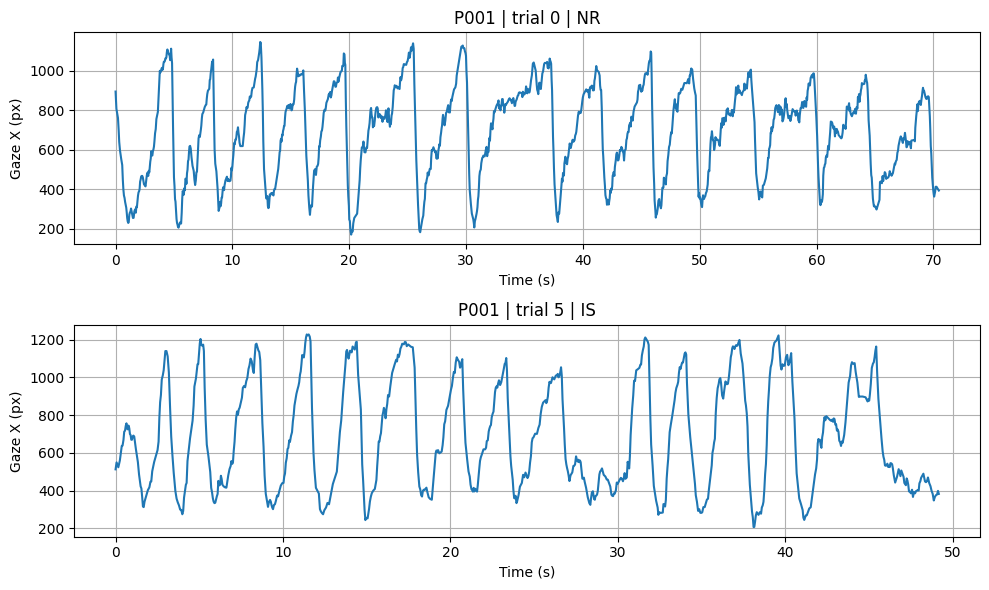

저장 완료:
analysis/results/figures/gaze_nr_is.png
analysis/results/pilot_features.csv
analysis/results/pilot_metadata.json
analysis/results/pilot_quality.csv
주의: 다운로드한 원본 파일 및 작업자 ID는 이 결과 CSV에 없습니다.


In [13]:
# STEP 4. 그래프 만들고 결과 CSV·메타데이터를 정해진 경로에 저장
base = Path("analysis/results")
figdir = base / "figures"
figdir.mkdir(parents=True, exist_ok=True)

p = participants[0]
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
for ax, trial in zip(axes, [0, 5]):
    name = p["info"].get(f"trial_{trial}_name")
    condition = p["info"].get(f"trial_{trial}_condition", "unknown")
    if name not in p["raw"]:
        ax.set_title("Trial not available")
        continue
    points = p["raw"][name]
    if isinstance(points, str):
        points = json.loads(points)
    gaze = pd.DataFrame(points, columns=["x", "y", "t"]).apply(pd.to_numeric, errors="coerce")
    t = (gaze["t"] - gaze["t"].iloc[0]) / 1000
    ax.plot(t, gaze["x"])
    ax.set(title=f"{p['pid']} | trial {trial} | {condition.upper()}", xlabel="Time (s)", ylabel="Gaze X (px)")
    ax.grid(True)
plt.tight_layout()
plt.savefig(figdir / "gaze_nr_is.png", dpi=150)
plt.show()

feature_df.to_csv(base / "pilot_features.csv", index=False, encoding="utf-8")
quality_df.to_csv(base / "pilot_quality.csv", index=False, encoding="utf-8")
metadata = {
    "dataset": REPO, "commit_sha": PINNED_SHA, "selected_language": "EN", "files_requested": N_FILES,
    "files_loaded": len(participants), "unique_participants": len(alias_map),
    "license": "CC BY 4.0", "max_gap_ms": MAX_GAP_MS,
    "quality_thresholds_status": "exploratory_not_validated",
    "min_rate_hz": MIN_RATE_HZ, "min_roi": MIN_ROI, "max_offset": MAX_OFFSET,
    "python_version": sys.version.split()[0],
    "pandas_version": pd.__version__, "numpy_version": np.__version__,
    "matplotlib_version": plt.matplotlib.__version__, "requests_version": requests.__version__,
}
(base / "pilot_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
print("저장 완료:")
for f in sorted(base.rglob("*")):
    if f.is_file():
        print(f)
print("주의: 다운로드한 원본 파일 및 작업자 ID는 이 결과 CSV에 없습니다.")

## 분석 해석 및 한계
- 현재 품질 플래그는 탐색적 후보 표시입니다. 10Hz 외 ROI·offset 수치는 팀 차원의 **임시 설정**으로 공통 검증이 필요합니다.
- NR/IS는 과제 조건이며 정독/훑기/응시의 정답 라벨이 아닙니다.
- 전체 화면 크기로 나눈 시선 좌표 이동량은 A의 상대 홍채 이동량과 동일한 특징이 아닙니다.
- `pilot_features.csv`는 동일 참가자의 반복 과제를 포함하므로 **행을 임의로 섞어 학습/검증 분할하면 안 됩니다.** 추후 참가자 기준으로 분리합니다.
- 큰 왼쪽 이동 후보 수는 A detector의 임계값이 정해진 후 **탐색적 보조 특징**으로 계산할 예정입니다. 현재는 실제 줄바꿈 사건이라고 주장하지 않습니다.
- 공유 저장소에는 참가자 작업자 ID, 대응표, 원본 JSON, 개인 영상이나 사용자 로그를 업로드하지 않습니다. 표·그림에도 원본 파일명을 표시하지 않습니다.
- 원본: Ribeiro et al. (2023), WebQAmGaze; https://github.com/tfnribeiro/WebQAmGaze ; CC BY 4.0 (표시·변경사항 표시 조건).
